In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import libraries

In [ ]:
import os
import json
import joblib
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Step 9 libraries loaded successfully.")

TensorFlow version: 2.20.0
Step 9 libraries loaded successfully.


Define project paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

LATENT_DIR = os.path.join(
    PROCESSED_DIR,
    "latent_features"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

SAE_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "stacked_autoencoder"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

PREDICTIONS_DIR = os.path.join(
    RESULTS_DIR,
    "predictions"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

for folder in [
    LATENT_DIR,
    SAE_MODEL_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    FIGURES_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )

print("Step 9 directories ready.")

Step 9 directories ready.


Check required files

In [ ]:
train_path = os.path.join(
    SUPERVISED_DIR,
    "train_supervised_28d.parquet"
)

val_path = os.path.join(
    SUPERVISED_DIR,
    "validation_supervised_28d.parquet"
)

test_path = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

config_path = os.path.join(
    SUPERVISED_DIR,
    "supervised_config.json"
)

scaler_path = os.path.join(
    MODEL_DIR,
    "neural_feature_scaler.pkl"
)

required_files = [
    train_path,
    val_path,
    test_path,
    config_path,
    scaler_path
]

all_exist = True

for path in required_files:

    if os.path.exists(path):
        print("FOUND   ->", path)

    else:
        print("MISSING ->", path)
        all_exist = False

if not all_exist:
    raise FileNotFoundError(
        "Required Step 5/6 files are missing."
    )

print("\nAll required files found.")

FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/train_supervised_28d.parquet
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/validation_supervised_28d.parquet
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/test_supervised_28d.parquet
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/supervised_config.json
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/models/neural_feature_scaler.pkl

All required files found.


Load datasets and configuration

In [ ]:
train_df = pd.read_parquet(
    train_path
)

val_df = pd.read_parquet(
    val_path
)

test_df = pd.read_parquet(
    test_path
)

with open(
    config_path,
    "r"
) as f:

    config = json.load(f)

FEATURES = config["features"]
TARGETS = config["targets"]

INPUT_DIM = len(FEATURES)
HORIZON = len(TARGETS)

# Final SAE latent dimension
LATENT_DIM = 8

print("=" * 60)
print("STEP 9 DATA")
print("=" * 60)

print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

print("\nInput features :", INPUT_DIM)
print("Forecast days  :", HORIZON)
print("Latent size    :", LATENT_DIM)

STEP 9 DATA
Train      : (79200, 71)
Validation : (300, 71)
Test       : (300, 71)

Input features : 40
Forecast days  : 28
Latent size    : 8


Clean feature data

In [ ]:
for col in FEATURES:

    train_df[col] = pd.to_numeric(
        train_df[col],
        errors="coerce"
    )

    val_df[col] = pd.to_numeric(
        val_df[col],
        errors="coerce"
    )

    test_df[col] = pd.to_numeric(
        test_df[col],
        errors="coerce"
    )


for dataset in [
    train_df,
    val_df,
    test_df
]:

    dataset[FEATURES] = (
        dataset[FEATURES]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )

In [ ]:
train_medians = (
    train_df[FEATURES]
    .median()
    .fillna(0)
)

train_df[FEATURES] = (
    train_df[FEATURES]
    .fillna(train_medians)
)

val_df[FEATURES] = (
    val_df[FEATURES]
    .fillna(train_medians)
)

test_df[FEATURES] = (
    test_df[FEATURES]
    .fillna(train_medians)
)

print(
    "Train NaN:",
    train_df[FEATURES].isna().sum().sum()
)

print(
    "Validation NaN:",
    val_df[FEATURES].isna().sum().sum()
)

print(
    "Test NaN:",
    test_df[FEATURES].isna().sum().sum()
)

Train NaN: 0
Validation NaN: 0
Test NaN: 0


Create X and y arrays

In [ ]:
X_train = train_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

X_val = val_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

X_test = test_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)


y_train = train_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

y_val = val_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

y_test = test_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (79200, 40)
y_train: (79200, 28)
X_val: (300, 40)
y_val: (300, 28)
X_test: (300, 40)
y_test: (300, 28)


Load scaler and standardize features

In [ ]:
scaler = joblib.load(
    scaler_path
)

X_train_scaled = scaler.transform(
    X_train
).astype(np.float32)

X_val_scaled = scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = scaler.transform(
    X_test
).astype(np.float32)

print(
    "Train:",
    X_train_scaled.shape
)

print(
    "Validation:",
    X_val_scaled.shape
)

print(
    "Test:",
    X_test_scaled.shape
)

print(
    "\nFinite train:",
    np.isfinite(
        X_train_scaled
    ).all()
)

Train: (79200, 40)
Validation: (300, 40)
Test: (300, 40)

Finite train: True


SAE Layer 1 pretraining: 41 → 32 → 41

In [ ]:
tf.keras.backend.clear_session()

layer1_input = Input(
    shape=(INPUT_DIM,),
    name="Layer1_Input"
)

layer1_encoded = Dense(
    32,
    activation="relu",
    name="Layer1_Encoder"
)(layer1_input)

layer1_decoded = Dense(
    INPUT_DIM,
    activation="linear",
    name="Layer1_Decoder"
)(layer1_encoded)

ae_layer1 = Model(
    inputs=layer1_input,
    outputs=layer1_decoded,
    name="SAE_Layer1_Pretraining"
)

encoder_layer1 = Model(
    inputs=layer1_input,
    outputs=layer1_encoded,
    name="SAE_Encoder_Layer1"
)

ae_layer1.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

ae_layer1.summary()

Model: "SAE_Layer1_Pretraining"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Layer1_Input (InputLayer)       │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer1_Encoder (Dense)          │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer1_Decoder (Dense)          │ (None, 40)             │         1,320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,632 (10.28 KB)

 Trainable params: 2,632 (10.28 KB)

 Non-trainable params: 0 (0.00 B)

Train Layer 1

In [ ]:
layer1_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

layer1_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_layer1 = ae_layer1.fit(

    X_train_scaled,
    X_train_scaled,

    validation_data=(
        X_val_scaled,
        X_val_scaled
    ),

    epochs=60,

    batch_size=256,

    callbacks=[
        layer1_early_stop,
        layer1_reduce_lr
    ],

    verbose=1
)

Epoch 1/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.4106 - val_loss: 1.0831 - learning_rate: 0.0010
Epoch 2/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1135 - val_loss: 1.0710 - learning_rate: 0.0010
Epoch 3/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0596 - val_loss: 1.0852 - learning_rate: 0.0010
Epoch 4/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0361 - val_loss: 1.1274 - learning_rate: 0.0010
Epoch 5/60
299/310 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0238
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0229 - val_loss: 1.1861 - learning_rate: 0.0010
Epoch 6/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0159 - val_loss: 1.2079 - learning_rate: 5.0000e-04
Epoch 7/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0125 - val_loss: 1.2264 - learning_rate: 5.0000e-04
Epoch 8/60
291/310 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0097
Epoch 8: ReduceLROnPlat

Extract first-level features

In [ ]:
H1_train = encoder_layer1.predict(
    X_train_scaled,
    batch_size=256,
    verbose=0
)

H1_val = encoder_layer1.predict(
    X_val_scaled,
    batch_size=256,
    verbose=0
)

H1_test = encoder_layer1.predict(
    X_test_scaled,
    batch_size=256,
    verbose=0
)

print(
    "Original:",
    X_train_scaled.shape
)

print(
    "Layer 1:",
    H1_train.shape
)

Original: (79200, 40)
Layer 1: (79200, 32)


SAE Layer 2 pretraining: 32 → 16 → 32

In [ ]:
layer2_input = Input(
    shape=(32,),
    name="Layer2_Input"
)

layer2_encoded = Dense(
    16,
    activation="relu",
    name="Layer2_Encoder"
)(layer2_input)

layer2_decoded = Dense(
    32,
    activation="linear",
    name="Layer2_Decoder"
)(layer2_encoded)

ae_layer2 = Model(
    inputs=layer2_input,
    outputs=layer2_decoded,
    name="SAE_Layer2_Pretraining"
)

encoder_layer2 = Model(
    inputs=layer2_input,
    outputs=layer2_encoded,
    name="SAE_Encoder_Layer2"
)

ae_layer2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

ae_layer2.summary()

Model: "SAE_Layer2_Pretraining"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Layer2_Input (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer2_Encoder (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer2_Decoder (Dense)          │ (None, 32)             │           544 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072 (4.19 KB)

 Trainable params: 1,072 (4.19 KB)

 Non-trainable params: 0 (0.00 B)

Train Layer 2

In [ ]:
layer2_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

layer2_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_layer2 = ae_layer2.fit(

    H1_train,
    H1_train,

    validation_data=(
        H1_val,
        H1_val
    ),

    epochs=60,

    batch_size=256,

    callbacks=[
        layer2_early_stop,
        layer2_reduce_lr
    ],

    verbose=1
)

Epoch 1/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5557 - val_loss: 0.8456 - learning_rate: 0.0010
Epoch 2/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1991 - val_loss: 0.5453 - learning_rate: 0.0010
Epoch 3/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1253 - val_loss: 0.4463 - learning_rate: 0.0010
Epoch 4/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0942 - val_loss: 0.3956 - learning_rate: 0.0010
Epoch 5/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0809 - val_loss: 0.3576 - learning_rate: 0.0010
Epoch 6/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0741 - val_loss: 0.3396 - learning_rate: 0.0010
Epoch 7/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0705 - val_loss: 0.3321 - learning_rate: 0.0010
Epoch 8/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0676 - val_loss: 0.3289 - learning_rate: 0.0010
Epoch 9/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0612 - val_loss: 0.3227 - learning_rate: 0.0010
Epoch 10/6

Extract second-level features

In [ ]:
H2_train = encoder_layer2.predict(
    H1_train,
    batch_size=256,
    verbose=0
)

H2_val = encoder_layer2.predict(
    H1_val,
    batch_size=256,
    verbose=0
)

H2_test = encoder_layer2.predict(
    H1_test,
    batch_size=256,
    verbose=0
)

print(
    "Layer 1:",
    H1_train.shape
)

print(
    "Layer 2:",
    H2_train.shape
)

Layer 1: (79200, 32)
Layer 2: (79200, 16)


SAE Layer 3 pretraining: 16 → 8 → 16

In [ ]:
layer3_input = Input(
    shape=(16,),
    name="Layer3_Input"
)

layer3_encoded = Dense(
    LATENT_DIM,
    activation="linear",
    name="Layer3_Encoder"
)(layer3_input)

layer3_decoded = Dense(
    16,
    activation="linear",
    name="Layer3_Decoder"
)(layer3_encoded)

ae_layer3 = Model(
    inputs=layer3_input,
    outputs=layer3_decoded,
    name="SAE_Layer3_Pretraining"
)

encoder_layer3 = Model(
    inputs=layer3_input,
    outputs=layer3_encoded,
    name="SAE_Encoder_Layer3"
)

ae_layer3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

ae_layer3.summary()

Model: "SAE_Layer3_Pretraining"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Layer3_Input (InputLayer)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer3_Encoder (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer3_Decoder (Dense)          │ (None, 16)             │           144 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 280 (1.09 KB)

 Trainable params: 280 (1.09 KB)

 Non-trainable params: 0 (0.00 B)

Train Layer 3

In [ ]:
layer3_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

layer3_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_layer3 = ae_layer3.fit(

    H2_train,
    H2_train,

    validation_data=(
        H2_val,
        H2_val
    ),

    epochs=60,

    batch_size=256,

    callbacks=[
        layer3_early_stop,
        layer3_reduce_lr
    ],

    verbose=1
)

Epoch 1/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6492 - val_loss: 1.8408 - learning_rate: 0.0010
Epoch 2/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6416 - val_loss: 1.0044 - learning_rate: 0.0010
Epoch 3/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4487 - val_loss: 0.6547 - learning_rate: 0.0010
Epoch 4/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3584 - val_loss: 0.5940 - learning_rate: 0.0010
Epoch 5/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3036 - val_loss: 0.5675 - learning_rate: 0.0010
Epoch 6/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2620 - val_loss: 0.5127 - learning_rate: 0.0010
Epoch 7/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2327 - val_loss: 0.4554 - learning_rate: 0.0010
Epoch 8/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2144 - val_loss: 0.4145 - learning_rate: 0.0010
Epoch 9/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2025 - val_loss: 0.3882 - learning_rate: 0.0010
Epoch 10/6

Construct complete Stacked Autoencoder

In [ ]:
sae_input = Input(
    shape=(INPUT_DIM,),
    name="SAE_Input"
)

# Encoder
x = Dense(
    32,
    activation="relu",
    name="SAE_Encoder_32"
)(sae_input)

x = Dense(
    16,
    activation="relu",
    name="SAE_Encoder_16"
)(x)

sae_latent = Dense(
    LATENT_DIM,
    activation="linear",
    name="SAE_Latent"
)(x)

# Decoder
x = Dense(
    16,
    activation="relu",
    name="SAE_Decoder_16"
)(sae_latent)

x = Dense(
    32,
    activation="relu",
    name="SAE_Decoder_32"
)(x)

sae_output = Dense(
    INPUT_DIM,
    activation="linear",
    name="SAE_Output"
)(x)

stacked_autoencoder = Model(
    inputs=sae_input,
    outputs=sae_output,
    name="Stacked_Autoencoder"
)

sae_encoder = Model(
    inputs=sae_input,
    outputs=sae_latent,
    name="SAE_Encoder"
)

stacked_autoencoder.summary()

Model: "Stacked_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ SAE_Input (InputLayer)          │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SAE_Encoder_32 (Dense)          │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SAE_Encoder_16 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SAE_Latent (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SAE_Decoder_16 (Dense)          │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SAE_Decoder_32 (Dense)          │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SAE_Output (Dense)              │ (None, 40)             │         1,320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,984 (15.56 KB)

 Trainable params: 3,984 (15.56 KB)

 Non-trainable params: 0 (0.00 B)

Transfer pretrained encoder weights

In [ ]:
stacked_autoencoder.get_layer(
    "SAE_Encoder_32"
).set_weights(
    ae_layer1.get_layer(
        "Layer1_Encoder"
    ).get_weights()
)

stacked_autoencoder.get_layer(
    "SAE_Encoder_16"
).set_weights(
    ae_layer2.get_layer(
        "Layer2_Encoder"
    ).get_weights()
)

stacked_autoencoder.get_layer(
    "SAE_Latent"
).set_weights(
    ae_layer3.get_layer(
        "Layer3_Encoder"
    ).get_weights()
)

print(
    "Pretrained encoder weights transferred successfully."
)

Pretrained encoder weights transferred successfully.


Compile complete SAE

In [ ]:
stacked_autoencoder.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),

    loss="mse",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="reconstruction_mae"
        )
    ]
)

print(
    "Stacked Autoencoder compiled."
)

Stacked Autoencoder compiled.


Define SAE callbacks

In [ ]:
BEST_SAE_PATH = os.path.join(
    SAE_MODEL_DIR,
    "best_sae.keras"
)

sae_early_stop = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True,

    verbose=1
)

sae_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=5,

    min_lr=1e-6,

    verbose=1
)

sae_checkpoint = ModelCheckpoint(

    BEST_SAE_PATH,

    monitor="val_loss",

    save_best_only=True,

    verbose=1
)

Fine-tune complete SAE

In [ ]:
history_sae = stacked_autoencoder.fit(

    X_train_scaled,
    X_train_scaled,

    validation_data=(
        X_val_scaled,
        X_val_scaled
    ),

    epochs=100,

    batch_size=256,

    shuffle=True,

    callbacks=[
        sae_early_stop,
        sae_reduce_lr,
        sae_checkpoint
    ],

    verbose=1
)

Epoch 1/100
299/310 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8357 - reconstruction_mae: 0.6147
Epoch 1: val_loss improved from None to 1.52921, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/stacked_autoencoder/best_sae.keras

Epoch 1: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/stacked_autoencoder/best_sae.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6369 - reconstruction_mae: 0.5320 - val_loss: 1.5292 - val_reconstruction_mae: 0.7839 - learning_rate: 5.0000e-04
Epoch 2/100
300/310 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3580 - reconstruction_mae: 0.3867
Epoch 2: val_loss improved from 1.52921 to 1.14925, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/stacked_autoencoder/best_sae.keras

Epoch 2: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/stacked_autoencoder/best_sae.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3257 - reconstruction_mae: 

Plot SAE reconstruction loss

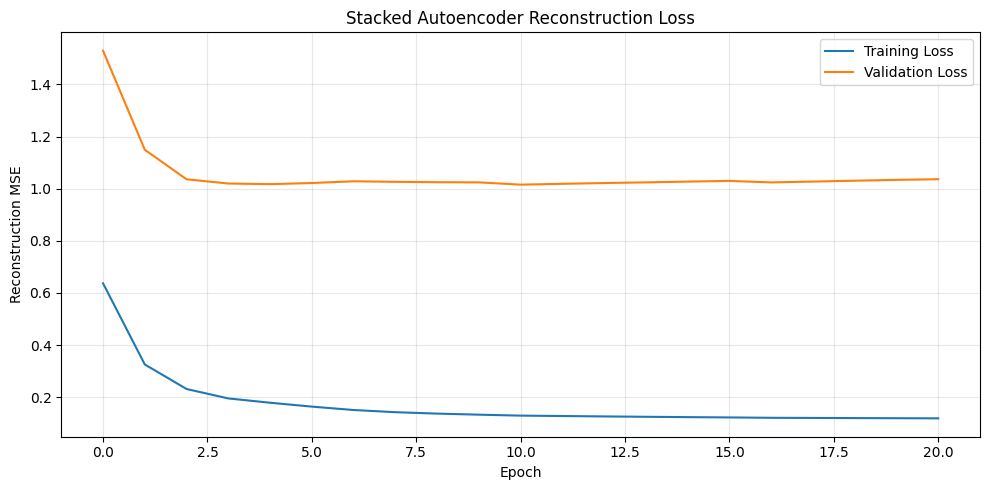

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_sae.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_sae.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")

plt.title(
    "Stacked Autoencoder Reconstruction Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

SAE_LOSS_PATH = os.path.join(
    FIGURES_DIR,
    "sae_reconstruction_loss.png"
)

plt.savefig(
    SAE_LOSS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Generate SAE reconstructions

In [ ]:
train_sae_reconstruction = (
    stacked_autoencoder.predict(
        X_train_scaled,
        batch_size=256,
        verbose=0
    )
)

val_sae_reconstruction = (
    stacked_autoencoder.predict(
        X_val_scaled,
        batch_size=256,
        verbose=0
    )
)

test_sae_reconstruction = (
    stacked_autoencoder.predict(
        X_test_scaled,
        batch_size=256,
        verbose=0
    )
)

Calculate reconstruction metrics

In [ ]:
def reconstruction_metrics(
    original,
    reconstructed
):

    mse = np.mean(
        (
            original -
            reconstructed
        ) ** 2
    )

    mae = np.mean(
        np.abs(
            original -
            reconstructed
        )
    )

    return float(mse), float(mae)

In [ ]:
train_sae_mse, train_sae_mae = (
    reconstruction_metrics(
        X_train_scaled,
        train_sae_reconstruction
    )
)

val_sae_mse, val_sae_mae = (
    reconstruction_metrics(
        X_val_scaled,
        val_sae_reconstruction
    )
)

test_sae_mse, test_sae_mae = (
    reconstruction_metrics(
        X_test_scaled,
        test_sae_reconstruction
    )
)

print("=" * 60)
print("SAE RECONSTRUCTION RESULTS")
print("=" * 60)

print(
    f"Train MSE      : {train_sae_mse:.6f}"
)

print(
    f"Validation MSE : {val_sae_mse:.6f}"
)

print(
    f"Test MSE       : {test_sae_mse:.6f}"
)

print()

print(
    f"Train MAE      : {train_sae_mae:.6f}"
)

print(
    f"Validation MAE : {val_sae_mae:.6f}"
)

print(
    f"Test MAE       : {test_sae_mae:.6f}"
)

SAE RECONSTRUCTION RESULTS
Train MSE      : 0.127766
Validation MSE : 1.015393
Test MSE       : 0.933666

Train MAE      : 0.191972
Validation MAE : 0.521913
Test MAE       : 0.463418


Save SAE reconstruction metrics

In [ ]:
sae_reconstruction_df = pd.DataFrame({

    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],

    "Reconstruction_MSE": [
        train_sae_mse,
        val_sae_mse,
        test_sae_mse
    ],

    "Reconstruction_MAE": [
        train_sae_mae,
        val_sae_mae,
        test_sae_mae
    ]
})

display(
    sae_reconstruction_df.round(6)
)

SAE_RECON_PATH = os.path.join(
    METRICS_DIR,
    "sae_reconstruction_metrics.csv"
)

sae_reconstruction_df.to_csv(
    SAE_RECON_PATH,
    index=False
)

print(
    "Saved:",
    SAE_RECON_PATH
)

,Dataset,Reconstruction_MSE,Reconstruction_MAE
0,Train,0.127766,0.191972
1,Validation,1.015393,0.521913
2,Test,0.933666,0.463418


Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/sae_reconstruction_metrics.csv


Extract SAE latent features

In [ ]:
Z_train_sae = sae_encoder.predict(
    X_train_scaled,
    batch_size=256,
    verbose=0
)

Z_val_sae = sae_encoder.predict(
    X_val_scaled,
    batch_size=256,
    verbose=0
)

Z_test_sae = sae_encoder.predict(
    X_test_scaled,
    batch_size=256,
    verbose=0
)

print("=" * 60)
print("SAE LATENT FEATURES")
print("=" * 60)

print(
    X_train_scaled.shape,
    "->",
    Z_train_sae.shape
)

print(
    X_val_scaled.shape,
    "->",
    Z_val_sae.shape
)

print(
    X_test_scaled.shape,
    "->",
    Z_test_sae.shape
)

SAE LATENT FEATURES
(79200, 40) -> (79200, 8)
(300, 40) -> (300, 8)
(300, 40) -> (300, 8)


Verify SAE latent features

In [ ]:
print(
    "Train finite:",
    np.isfinite(
        Z_train_sae
    ).all()
)

print(
    "Validation finite:",
    np.isfinite(
        Z_val_sae
    ).all()
)

print(
    "Test finite:",
    np.isfinite(
        Z_test_sae
    ).all()
)

print(
    "\nLatent mean:",
    np.mean(
        Z_train_sae
    )
)

print(
    "Latent std:",
    np.std(
        Z_train_sae
    )
)

Train finite: True
Validation finite: True
Test finite: True

Latent mean: -0.25033242
Latent std: 6.327945


Create SAE latent dataset

In [ ]:
SAE_LATENT_FEATURES = [
    f"SAE_Latent_{i}"
    for i in range(
        1,
        LATENT_DIM + 1
    )
]

print(
    SAE_LATENT_FEATURES
)

['SAE_Latent_1', 'SAE_Latent_2', 'SAE_Latent_3', 'SAE_Latent_4', 'SAE_Latent_5', 'SAE_Latent_6', 'SAE_Latent_7', 'SAE_Latent_8']


In [ ]:
train_sae_latent_df = pd.DataFrame(
    Z_train_sae,
    columns=SAE_LATENT_FEATURES
)

val_sae_latent_df = pd.DataFrame(
    Z_val_sae,
    columns=SAE_LATENT_FEATURES
)

test_sae_latent_df = pd.DataFrame(
    Z_test_sae,
    columns=SAE_LATENT_FEATURES
)

In [ ]:
ID_COLUMNS = [
    col
    for col in [
        "id",
        "series_key",
        "date"
    ]
    if col in train_df.columns
]

for col in ID_COLUMNS:

    train_sae_latent_df[col] = (
        train_df[col]
        .reset_index(drop=True)
    )

    val_sae_latent_df[col] = (
        val_df[col]
        .reset_index(drop=True)
    )

    test_sae_latent_df[col] = (
        test_df[col]
        .reset_index(drop=True)
    )

In [ ]:
for target in TARGETS:

    train_sae_latent_df[target] = (
        train_df[target]
        .reset_index(drop=True)
    )

    val_sae_latent_df[target] = (
        val_df[target]
        .reset_index(drop=True)
    )

    test_sae_latent_df[target] = (
        test_df[target]
        .reset_index(drop=True)
    )

print(
    "Train latent:",
    train_sae_latent_df.shape
)

print(
    "Validation latent:",
    val_sae_latent_df.shape
)

print(
    "Test latent:",
    test_sae_latent_df.shape
)

display(
    train_sae_latent_df.head()
)

Train latent: (79200, 39)
Validation latent: (300, 39)
Test latent: (300, 39)


,SAE_Latent_1,SAE_Latent_2,SAE_Latent_3,SAE_Latent_4,SAE_Latent_5,SAE_Latent_6,SAE_Latent_7,SAE_Latent_8,id,series_key,...,target_day_19,target_day_20,target_day_21,target_day_22,target_day_23,target_day_24,target_day_25,target_day_26,target_day_27,target_day_28
0,2.115768,3.609456,-0.691618,-2.766529,-0.566143,4.337732,-4.424115,-4.081419,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,1.0,2.0,1.0,2.0,1.0,0.0,0.0,3.0,2.0,1.0
1,2.084649,3.770954,-1.077709,-2.758546,-0.677562,4.989898,-4.871845,-4.000398,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,3.0,2.0,1.0,0.0,2.0,2.0,0.0,1.0,0.0,0.0
2,3.779971,2.869694,-0.821229,-1.865651,-0.842940,3.884741,-3.946767,-3.967689,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0
3,2.932750,3.660006,-2.414918,-1.828508,-2.463915,5.013205,-5.740639,-3.456278,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,0.0,2.0,0.0,3.0,1.0,3.0,0.0,2.0,0.0,2.0
4,2.646294,3.479974,-1.906074,-1.746976,-2.382521,4.535358,-5.139390,-2.747917,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,2.0,0.0,2.0,3.0,4.0,5.0,5.0,6.0,7.0,2.0


Save SAE latent datasets

In [ ]:
SAE_TRAIN_PATH = os.path.join(
    LATENT_DIR,
    "sae_train_latent.parquet"
)

SAE_VAL_PATH = os.path.join(
    LATENT_DIR,
    "sae_validation_latent.parquet"
)

SAE_TEST_PATH = os.path.join(
    LATENT_DIR,
    "sae_test_latent.parquet"
)

train_sae_latent_df.to_parquet(
    SAE_TRAIN_PATH,
    index=False
)

val_sae_latent_df.to_parquet(
    SAE_VAL_PATH,
    index=False
)

test_sae_latent_df.to_parquet(
    SAE_TEST_PATH,
    index=False
)

print(
    "SAE latent datasets saved."
)

SAE latent datasets saved.


Save SAE models

In [ ]:
SAE_MODEL_PATH = os.path.join(
    SAE_MODEL_DIR,
    "sae_final.keras"
)

SAE_ENCODER_PATH = os.path.join(
    SAE_MODEL_DIR,
    "sae_encoder.keras"
)

stacked_autoencoder.save(
    SAE_MODEL_PATH
)

sae_encoder.save(
    SAE_ENCODER_PATH
)

print(
    "SAE saved:",
    SAE_MODEL_PATH
)

print(
    "SAE encoder saved:",
    SAE_ENCODER_PATH
)

SAE saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/stacked_autoencoder/sae_final.keras
SAE encoder saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/stacked_autoencoder/sae_encoder.keras


Save SAE configuration

In [ ]:
sae_config = {

    "model":
        "Stacked Autoencoder",

    "input_dimension":
        INPUT_DIM,

    "latent_dimension":
        LATENT_DIM,

    "encoder_architecture": [
        INPUT_DIM,
        32,
        16,
        LATENT_DIM
    ],

    "decoder_architecture": [
        LATENT_DIM,
        16,
        32,
        INPUT_DIM
    ],

    "pretraining":
        "Greedy layer-wise pretraining",

    "fine_tuning":
        "End-to-end",

    "reconstruction_loss":
        "MSE",

    "latent_features":
        SAE_LATENT_FEATURES
}

SAE_CONFIG_PATH = os.path.join(
    SAE_MODEL_DIR,
    "sae_config.json"
)

with open(
    SAE_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        sae_config,
        f,
        indent=4
    )

print(
    "SAE configuration saved."
)

SAE configuration saved.


PCA visualization of SAE latent space

In [ ]:
from sklearn.decomposition import PCA

sae_pca = PCA(
    n_components=2,
    random_state=SEED
)

Z_sae_pca = sae_pca.fit_transform(
    Z_train_sae
)

print(
    "Explained variance:",
    sae_pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    sae_pca.explained_variance_ratio_.sum()
)

Explained variance: [0.6354722  0.14585161]
Total explained variance: 0.7813238


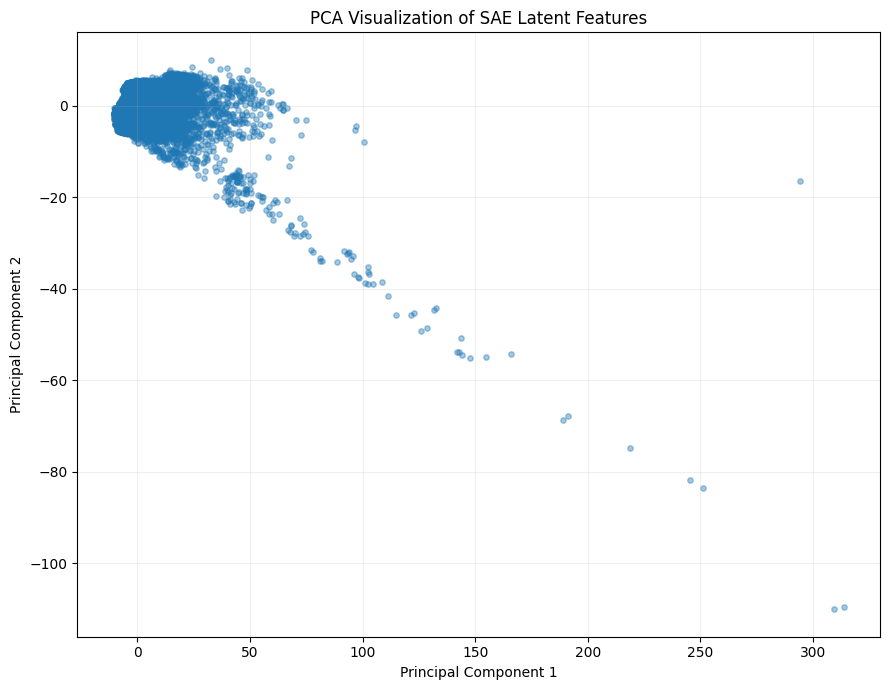

In [ ]:
plt.figure(
    figsize=(9, 7)
)

plt.scatter(
    Z_sae_pca[:, 0],
    Z_sae_pca[:, 1],
    alpha=0.4,
    s=15
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.title(
    "PCA Visualization of SAE Latent Features"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

SAE_PCA_PATH = os.path.join(
    FIGURES_DIR,
    "sae_latent_pca.png"
)

plt.savefig(
    SAE_PCA_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Build SAE + MLP forecasting model

In [ ]:
tf.keras.backend.clear_session()

sae_mlp_model = tf.keras.Sequential([

    Input(
        shape=(LATENT_DIM,)
    ),

    Dense(
        64,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(
        0.20
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(
        0.10
    ),

    Dense(
        HORIZON,
        activation="linear"
    )
])

sae_mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 28)             │           924 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,836 (14.98 KB)

 Trainable params: 3,708 (14.48 KB)

 Non-trainable params: 128 (512.00 B)

Compile SAE + MLP

In [ ]:
sae_mlp_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mae",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        )
    ]
)

sae_mlp_early_stop = EarlyStopping(

    monitor="val_loss",

    patience=8,

    restore_best_weights=True,

    verbose=1
)

sae_mlp_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=4,

    min_lr=1e-6,

    verbose=1
)

print(
    "SAE + MLP compiled successfully."
)

SAE + MLP compiled successfully.


Train SAE + MLP

In [ ]:
history_sae_mlp = sae_mlp_model.fit(

    Z_train_sae,
    y_train,

    validation_data=(
        Z_val_sae,
        y_val
    ),

    epochs=60,

    batch_size=256,

    callbacks=[
        sae_mlp_early_stop,
        sae_mlp_reduce_lr
    ],

    verbose=1
)

Epoch 1/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.7949 - mae: 0.7949 - val_loss: 0.9136 - val_mae: 0.9136 - learning_rate: 0.0010
Epoch 2/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7010 - mae: 0.7010 - val_loss: 0.9095 - val_mae: 0.9095 - learning_rate: 0.0010
Epoch 3/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6961 - mae: 0.6961 - val_loss: 0.9022 - val_mae: 0.9022 - learning_rate: 0.0010
Epoch 4/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.6930 - mae: 0.6930 - val_loss: 0.8971 - val_mae: 0.8971 - learning_rate: 0.0010
Epoch 5/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.6918 - mae: 0.6918 - val_loss: 0.9001 - val_mae: 0.9001 - learning_rate: 0.0010
Epoch 6/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.6906 - mae: 0.6906 - val_loss: 0.8993 - val_mae: 0.8993 - learning_rate: 0.0010
Epoch 7/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.6889 - mae: 0.6889 - val_loss: 0.8917 - val_mae: 0.8917 - learning_rate: 0.0010
Epoch 

Generate 28-day predictions

In [ ]:
val_pred_sae_mlp = (
    sae_mlp_model.predict(
        Z_val_sae,
        batch_size=256,
        verbose=0
    )
)

test_pred_sae_mlp = (
    sae_mlp_model.predict(
        Z_test_sae,
        batch_size=256,
        verbose=0
    )
)

val_pred_sae_mlp = np.clip(
    val_pred_sae_mlp,
    0,
    None
)

test_pred_sae_mlp = np.clip(
    test_pred_sae_mlp,
    0,
    None
)

print(
    "Validation:",
    val_pred_sae_mlp.shape
)

print(
    "Test:",
    test_pred_sae_mlp.shape
)

Validation: (300, 28)
Test: (300, 28)


Define forecasting metrics

In [ ]:
def forecast_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    y_pred = np.clip(
        y_pred,
        0,
        None
    )

    # MAE
    mae = np.mean(
        np.abs(
            y_true -
            y_pred
        )
    )

    # RMSE
    rmse = np.sqrt(
        np.mean(
            (
                y_true -
                y_pred
            ) ** 2
        )
    )

    # WAPE
    denominator = np.sum(
        np.abs(y_true)
    )

    if denominator > 0:

        wape = (
            np.sum(
                np.abs(
                    y_true -
                    y_pred
                )
            )
            /
            denominator
        ) * 100

    else:
        wape = np.nan

    # sMAPE
    smape_denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    smape_numerator = (
        2 *
        np.abs(
            y_true -
            y_pred
        )
    )

    smape_values = np.divide(

        smape_numerator,

        smape_denominator,

        out=np.zeros_like(
            smape_numerator,
            dtype=np.float64
        ),

        where=(
            smape_denominator != 0
        )
    )

    smape = (
        np.mean(
            smape_values
        ) * 100
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "WAPE": float(wape),
        "sMAPE": float(smape)
    }

Evaluate SAE + MLP

In [ ]:
sae_mlp_val_metrics = forecast_metrics(
    y_val,
    val_pred_sae_mlp
)

sae_mlp_test_metrics = forecast_metrics(
    y_test,
    test_pred_sae_mlp
)

print("=" * 60)
print("SAE + MLP RESULTS")
print("=" * 60)

print("\nVALIDATION")

for metric, value in (
    sae_mlp_val_metrics.items()
):

    print(
        f"{metric:8s}: {value:.4f}"
    )

print("\nTEST")

for metric, value in (
    sae_mlp_test_metrics.items()
):

    print(
        f"{metric:8s}: {value:.4f}"
    )

SAE + MLP RESULTS

VALIDATION
MAE     : 0.8800
RMSE    : 1.8044
WAPE    : 74.7076
sMAPE   : 127.8439

TEST
MAE     : 0.9248
RMSE    : 1.9480
WAPE    : 77.9485
sMAPE   : 125.4724


Save SAE + MLP model

In [ ]:
SAE_MLP_MODEL_PATH = os.path.join(
    SAE_MODEL_DIR,
    "sae_mlp_forecaster.keras"
)

sae_mlp_model.save(
    SAE_MLP_MODEL_PATH
)

print(
    "SAE + MLP model saved:"
)

print(
    SAE_MLP_MODEL_PATH
)

SAE + MLP model saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/models/stacked_autoencoder/sae_mlp_forecaster.keras


Save SAE predictions

In [ ]:
if "series_key" in test_df.columns:

    test_ids = (
        test_df[
            "series_key"
        ]
        .astype(str)
        .values
    )

else:

    test_ids = (
        test_df[
            "id"
        ]
        .astype(str)
        .values
    )

prediction_records = []

for i in range(
    len(test_df)
):

    for h in range(
        HORIZON
    ):

        prediction_records.append({

            "series_id":
                test_ids[i],

            "forecast_day":
                h + 1,

            "actual":
                float(
                    y_test[i, h]
                ),

            "prediction":
                float(
                    test_pred_sae_mlp[
                        i,
                        h
                    ]
                ),

            "model":
                "SAE + MLP"
        })

sae_predictions_df = pd.DataFrame(
    prediction_records
)

display(
    sae_predictions_df.head()
)

,series_id,forecast_day,actual,prediction,model
0,FOODS_1_005_TX_3,1,1.0,0.000000,SAE + MLP
1,FOODS_1_005_TX_3,2,0.0,0.000000,SAE + MLP
2,FOODS_1_005_TX_3,3,4.0,0.000000,SAE + MLP
3,FOODS_1_005_TX_3,4,1.0,0.000034,SAE + MLP
4,FOODS_1_005_TX_3,5,1.0,0.000000,SAE + MLP


In [ ]:
SAE_PREDICTION_PATH = os.path.join(
    PREDICTIONS_DIR,
    "sae_mlp_test_predictions.csv"
)

sae_predictions_df.to_csv(
    SAE_PREDICTION_PATH,
    index=False
)

print(
    "Predictions saved:",
    SAE_PREDICTION_PATH
)

Predictions saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/predictions/sae_mlp_test_predictions.csv


Compare AE, DAE and SAE models

In [ ]:
dae_comparison_path = os.path.join(
    METRICS_DIR,
    "dae_model_comparison.csv"
)

if os.path.exists(
    dae_comparison_path
):

    comparison_df = pd.read_csv(
        dae_comparison_path
    )

else:

    baseline_path = os.path.join(
        METRICS_DIR,
        "baseline_test_metrics.csv"
    )

    comparison_df = pd.read_csv(
        baseline_path
    )

In [ ]:
sae_result = pd.DataFrame([{

    "Model":
        "SAE + MLP",

    "MAE":
        sae_mlp_test_metrics["MAE"],

    "RMSE":
        sae_mlp_test_metrics["RMSE"],

    "WAPE":
        sae_mlp_test_metrics["WAPE"],

    "sMAPE":
        sae_mlp_test_metrics["sMAPE"]
}])

In [ ]:
comparison_df = (
    comparison_df[
        comparison_df["Model"]
        != "SAE + MLP"
    ]
    .copy()
)

final_representation_comparison = (
    pd.concat(
        [
            comparison_df,
            sae_result
        ],
        ignore_index=True
    )
)

display(
    final_representation_comparison.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398
5,SAE + MLP,0.9248,1.9480,77.9485,125.4724


Save complete model comparison



In [ ]:
REPRESENTATION_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "representation_learning_model_comparison.csv"
)

final_representation_comparison.to_csv(
    REPRESENTATION_COMPARISON_PATH,
    index=False
)

print(
    "Comparison saved:"
)

print(
    REPRESENTATION_COMPARISON_PATH
)

Comparison saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/representation_learning_model_comparison.csv


Compare reconstruction performance

In [ ]:
reconstruction_tables = []

ae_path = os.path.join(
    METRICS_DIR,
    "ae_reconstruction_metrics.csv"
)

dae_path = os.path.join(
    METRICS_DIR,
    "dae_reconstruction_metrics.csv"
)

if os.path.exists(ae_path):

    ae_rec = pd.read_csv(
        ae_path
    )

    ae_rec["Model"] = "AE"

    reconstruction_tables.append(
        ae_rec
    )


if os.path.exists(dae_path):

    dae_rec = pd.read_csv(
        dae_path
    )

    dae_rec["Model"] = "DAE"

    reconstruction_tables.append(
        dae_rec
    )


sae_rec = (
    sae_reconstruction_df.copy()
)

sae_rec["Model"] = "SAE"

reconstruction_tables.append(
    sae_rec
)

reconstruction_comparison = pd.concat(
    reconstruction_tables,
    ignore_index=True
)

display(
    reconstruction_comparison.round(6)
)

,Dataset,Reconstruction_MSE,Reconstruction_MAE,Model
0,Train,0.170813,0.233573,AE
1,Validation,1.276855,0.709960,AE
2,Test,1.231944,0.692925,AE
3,Train,0.076345,0.145318,DAE
4,Validation,0.829169,0.378841,DAE
5,Test,0.832220,0.377377,DAE
6,Train,0.127766,0.191972,SAE
7,Validation,1.015393,0.521913,SAE
8,Test,0.933666,0.463418,SAE


In [ ]:
RECON_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "ae_dae_sae_reconstruction_comparison.csv"
)

reconstruction_comparison.to_csv(
    RECON_COMPARISON_PATH,
    index=False
)

28-day SAE horizon analysis

In [ ]:
sae_horizon_mae = np.mean(
    np.abs(
        y_test -
        test_pred_sae_mlp
    ),
    axis=0
)

sae_horizon_df = pd.DataFrame({

    "Forecast_Day":
        np.arange(
            1,
            HORIZON + 1
        ),

    "SAE_MLP_MAE":
        sae_horizon_mae
})

display(
    sae_horizon_df
)

,Forecast_Day,SAE_MLP_MAE
0,1,0.767668
1,2,0.853527
2,3,0.832315
3,4,0.838494
4,5,0.795165
5,6,0.911503
6,7,1.070638
7,8,0.802062
8,9,0.884521
9,10,0.765891


In [ ]:
SAE_HORIZON_PATH = os.path.join(
    METRICS_DIR,
    "sae_mlp_horizon_mae.csv"
)

sae_horizon_df.to_csv(
    SAE_HORIZON_PATH,
    index=False
)

Plot AE vs DAE vs SAE horizon errors

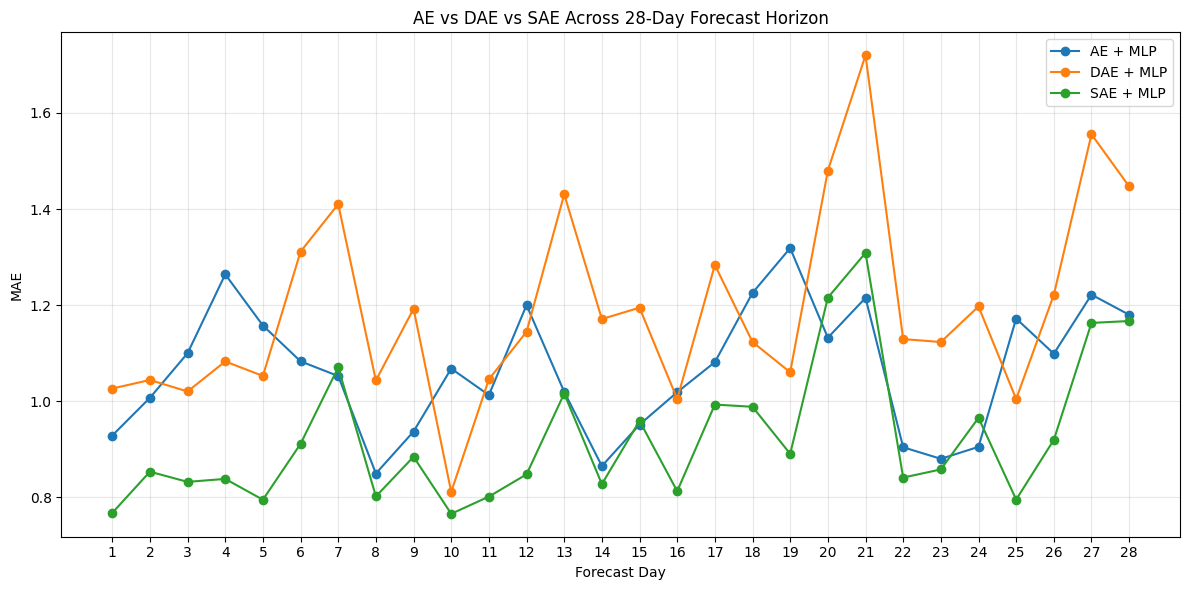

In [ ]:
plt.figure(
    figsize=(12, 6)
)

days = np.arange(
    1,
    HORIZON + 1
)

ae_horizon_path = os.path.join(
    METRICS_DIR,
    "ae_mlp_horizon_mae.csv"
)

dae_horizon_path = os.path.join(
    METRICS_DIR,
    "dae_mlp_horizon_mae.csv"
)


if os.path.exists(
    ae_horizon_path
):

    temp = pd.read_csv(
        ae_horizon_path
    )

    plt.plot(
        temp["Forecast_Day"],
        temp["AE_MLP_MAE"],
        marker="o",
        label="AE + MLP"
    )


if os.path.exists(
    dae_horizon_path
):

    temp = pd.read_csv(
        dae_horizon_path
    )

    plt.plot(
        temp["Forecast_Day"],
        temp["DAE_MLP_MAE"],
        marker="o",
        label="DAE + MLP"
    )


plt.plot(
    days,
    sae_horizon_mae,
    marker="o",
    label="SAE + MLP"
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "AE vs DAE vs SAE Across 28-Day Forecast Horizon"
)

plt.xticks(
    np.arange(
        1,
        29
    )
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

REPRESENTATION_PLOT_PATH = os.path.join(
    FIGURES_DIR,
    "ae_dae_sae_horizon_comparison.png"
)

plt.savefig(
    REPRESENTATION_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Plot SAE+MLP training history

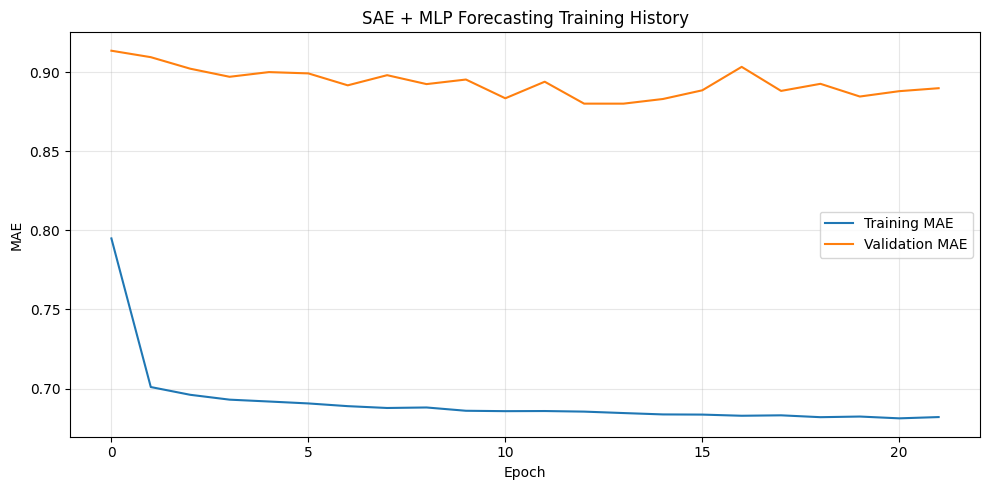

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_sae_mlp.history["loss"],
    label="Training MAE"
)

plt.plot(
    history_sae_mlp.history["val_loss"],
    label="Validation MAE"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "SAE + MLP Forecasting Training History"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

SAE_MLP_HISTORY_PATH = os.path.join(
    FIGURES_DIR,
    "sae_mlp_training_history.png"
)

plt.savefig(
    SAE_MLP_HISTORY_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Final verification

In [ ]:
print("=" * 78)
print("STEP 9 - STACKED AUTOENCODER FINAL VERIFICATION")
print("=" * 78)

print("\n1. SAE ARCHITECTURE")
print("-" * 45)

print(
    f"{INPUT_DIM} -> 32 -> 16 -> "
    f"{LATENT_DIM} -> 16 -> 32 -> "
    f"{INPUT_DIM}"
)


print("\n2. LAYER-WISE REPRESENTATION")
print("-" * 45)

print(
    "Original:",
    X_train_scaled.shape
)

print(
    "Layer 1:",
    H1_train.shape
)

print(
    "Layer 2:",
    H2_train.shape
)

print(
    "Final latent:",
    Z_train_sae.shape
)


print("\n3. SAE RECONSTRUCTION")
print("-" * 45)

print(
    f"Train MSE      : "
    f"{train_sae_mse:.6f}"
)

print(
    f"Validation MSE : "
    f"{val_sae_mse:.6f}"
)

print(
    f"Test MSE       : "
    f"{test_sae_mse:.6f}"
)


print("\n4. SAE + MLP TEST METRICS")
print("-" * 45)

for metric, value in (
    sae_mlp_test_metrics.items()
):

    print(
        f"{metric:8s}: "
        f"{value:.4f}"
    )


print("\n5. OUTPUT FILES")
print("-" * 45)

files_to_check = {

    "SAE Model":
        SAE_MODEL_PATH,

    "SAE Encoder":
        SAE_ENCODER_PATH,

    "SAE+MLP Model":
        SAE_MLP_MODEL_PATH,

    "SAE Train Latent":
        SAE_TRAIN_PATH,

    "SAE Validation Latent":
        SAE_VAL_PATH,

    "SAE Test Latent":
        SAE_TEST_PATH,

    "SAE Config":
        SAE_CONFIG_PATH,

    "SAE Predictions":
        SAE_PREDICTION_PATH,

    "Model Comparison":
        REPRESENTATION_COMPARISON_PATH
}

all_saved = True

for name, path in (
    files_to_check.items()
):

    exists = os.path.exists(
        path
    )

    print(
        f"{name:27s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_saved = False


print("\n" + "=" * 78)

if all_saved:

    print(
        "STEP 9 COMPLETED SUCCESSFULLY"
    )

    print(
        "41 FEATURES -> STACKED AE -> "
        "8 LATENT FEATURES -> MLP -> "
        "28-DAY FORECAST"
    )

else:

    print(
        "STEP 9 INCOMPLETE - "
        "CHECK THE MISSING FILES ABOVE"
    )

print("=" * 78)

STEP 9 - STACKED AUTOENCODER FINAL VERIFICATION

1. SAE ARCHITECTURE
---------------------------------------------
40 -> 32 -> 16 -> 8 -> 16 -> 32 -> 40

2. LAYER-WISE REPRESENTATION
---------------------------------------------
Original: (79200, 40)
Layer 1: (79200, 32)
Layer 2: (79200, 16)
Final latent: (79200, 8)

3. SAE RECONSTRUCTION
---------------------------------------------
Train MSE      : 0.127766
Validation MSE : 1.015393
Test MSE       : 0.933666

4. SAE + MLP TEST METRICS
---------------------------------------------
MAE     : 0.9248
RMSE    : 1.9480
WAPE    : 77.9485
sMAPE   : 125.4724

5. OUTPUT FILES
---------------------------------------------
SAE Model                  : FOUND
SAE Encoder                : FOUND
SAE+MLP Model              : FOUND
SAE Train Latent           : FOUND
SAE Validation Latent      : FOUND
SAE Test Latent            : FOUND
SAE Config                 : FOUND
SAE Predictions            : FOUND
Model Comparison           : FOUND

STEP 9 COMPL